<a id="top"></a>
# From Dynamics to Feedback with Uncertainty

This notebook is the technical reference for the six-part Akreon tutorial series. It develops the cartpole model from nonlinear dynamics through feedback, estimation, optimal control, and robust synthesis under parametric uncertainty.

## Contents

1. [Equations of motion](#part-1-equations-of-motion)
2. [Linearization and state-space analysis](#part-2-linearization-state-space)
3. [State-feedback synthesis via LMIs](#part-3-state-feedback-lmis)
4. [Luenberger observer synthesis and observer feedback](#part-4-observer-feedback)
5. [Optimal control with LQR and $H_2$ feedback](#part-5-optimal-control)
6. [Uncertainty modeling with polytopic LMIs](#part-6-uncertainty-modeling)

<a id="part-1-equations-of-motion"></a>
## Part 1 - Equations of Motion

Let $x$ denote cart position and let $\theta$ denote the pole angle measured from the unstable upright equilibrium. The input $u$ is the horizontal force applied to the cart. For cart mass $m_c$, pole mass $m_p$, pole half-length $l$, and gravity $g$, the nonlinear accelerations used for controller synthesis can be written as

$$
\ddot{x} = \frac{u + m_p \sin(\theta)\left(l\dot{\theta}^{2} - g\cos(\theta)\right)}{m_c + m_p\sin^{2}(\theta)},
$$

$$
\ddot{\theta} = \frac{g(m_c+m_p)\sin(\theta) - \cos(\theta)\left(u + m_p l\dot{\theta}^{2}\sin(\theta)\right)}{l\left(m_c + m_p\sin^{2}(\theta)\right)}.
$$

These coupled equations expose the nonlinear terms removed by local linearization: products of velocities, trigonometric state dependence, and a state-dependent denominator. Part 2 linearizes them about $\theta=0$, $\dot{\theta}=0$, and $u=0$ to obtain the model used throughout the remaining controller designs.

In [1]:
# ruff: noqa: F401, I001
import matplotlib.pyplot as plt
import control as ct  # used for sim and analysis
import gymnasium as gym  # use for simulating the cartpole
import numpy as np  # useful python lib for linalg
from IPython.display import display
from scipy.linalg import expm  # used for computing gramian
from scipy.integrate import quad_vec
import akreon_native.controls as controls
from akreon_native.controls import SolverConfig
from akreon_native.plot import (
    plot_poles,
    plot_state_step_responses,
    plot_state_trajectories,
    plot_shadow_price_summary,
    plot_rollout_states,
    show_rollout_frames,
)  # nice visualization / plotting util

In [2]:
# Call the installed control bindings directly.
print("Control bindings:", controls.__name__)


Control bindings: akreon_native.controls


<a id="part-2-linearization-state-space"></a>
## Part 2 - Linearization and State-Space Analysis

We start with the linearized state-space model about the steady-state equilibrium with the pendulum in the upright position.

$$
\begin{align*}
    & A = \begin{bmatrix}
        0.0 & 1.0 & 0.0 & 0.0 \\
        0.0 & 0.0 & -\frac{m_p g}{m_c} & 0.0 \\
        0.0 & 0.0 & 0.0 & 1.0 \\
        0.0 & 0.0 & \frac{(m_p+m_c)g}{m_c l} & 0.0 \\
    \end{bmatrix} \\
    & B = \begin{bmatrix}0 \\ \frac{1}{m_c} \\ 0 \\ -\frac{1}{m_c l} \end{bmatrix}
\end{align*}
$$

The state vector is 
$$
z = \begin{bmatrix}x & \dot{x} & \theta & \dot{\theta}\end{bmatrix}^{\mathsf T}
$$
where $x$ describes the cart position, $\dot{x}$ is the cart velocity, $\theta$ is the angular displacement of the pendulum from vertical, and $\dot{\theta}$ is the angular velocity of the pendulum.

The continuous-time state-space model is

$$
\dot{z} = A z + B u
$$

The parameters are based on Gymnasium's [CartPole environment](https://gymnasium.farama.org/environments/classic_control/cart_pole/).

In [3]:
# (1) acquire params of the cartpole from gym
STATE_LABELS = [
    "Cart Position\n$x$",
    "Cart Velocity\n$\\dot{x}$",
    "Pendulum Angle\n$\\theta$",
    "Angular Rate\n$\\dot{\\theta}$",
]

env = gym.make("CartPole-v1")
mc = env.unwrapped.masscart
mp = env.unwrapped.masspole
pole_length = env.unwrapped.length
gravity = env.unwrapped.gravity
CARTPOLE_DT = env.unwrapped.tau
env.close()

In [4]:
# (2) setup the linear state space model derived from the
# linearized euler-langrange equation from the dynamics video
A = np.array(
    [
        [0.0, 1.0, 0.0, 0.0],
        [0.0, 0.0, -(mp / mc) * gravity, 0.0],
        [0.0, 0.0, 0.0, 1.0],
        [0.0, 0.0, ((mp + mc) / (mc * pole_length)) * gravity, 0.0],
    ],
    dtype=np.float64,
)

B = np.array(
    [[0.0], [1.0 / mc], [0.0], [-1.0 / (mc * pole_length)]],
    dtype=np.float64,
)

C = np.array([[1.0, 0.0, 0.0, 0.0], [0.0, 0.0, 1.0, 0.0]], dtype=np.float64)
D = np.zeros((2, 1), dtype=np.float64)

cartpole_ss = ct.ss(A, B, C, D)

print(f"A = \n{A}")
print(f"B = \n{B}")
print(f"C = \n{C}")
print(f"D = \n{D}")

A = 
[[ 0.    1.    0.    0.  ]
 [ 0.    0.   -0.98  0.  ]
 [ 0.    0.    0.    1.  ]
 [ 0.    0.   21.56  0.  ]]
B = 
[[ 0.]
 [ 1.]
 [ 0.]
 [-2.]]
C = 
[[1. 0. 0. 0.]
 [0. 0. 1. 0.]]
D = 
[[0.]
 [0.]]


Open loop poles: [ 0.        +0.j  0.        +0.j  4.64327471+0.j -4.64327471+0.j]


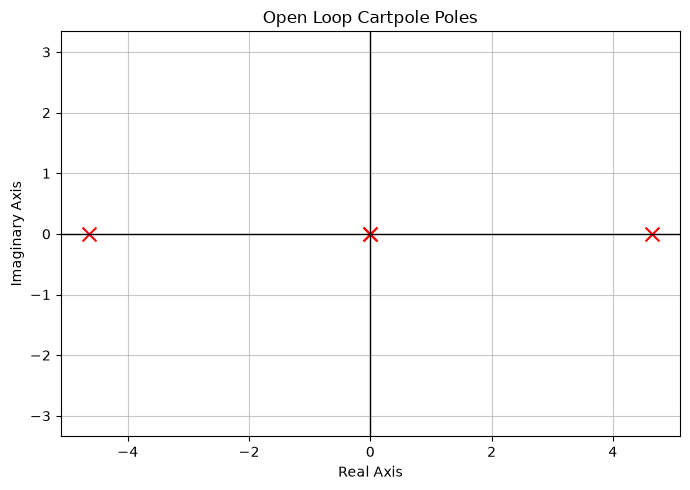

In [5]:
# (3) perform open-loop analysis of the cartpole system
# (3.a) analyze the poles of the open loop system
open_loop_poles = ct.poles(cartpole_ss)
print(f"Open loop poles: {open_loop_poles}")
plot_poles(open_loop_poles, title="Open Loop Cartpole Poles")

#### Cayley-Hamilton Controllability Matrix

The linear system is controllable if $\operatorname{rank}(\mathcal C)=n$, where $n$ is the number of states.

$$
\mathcal C = \begin{bmatrix}B & AB & A^2B & \cdots & A^{n-1}B\end{bmatrix}.
$$

In [6]:
# (3.b) determine if the system is controllable

# part 1 - Cayley-Hamilton controllability matrix C = [B AB ... A^(n-1)B]
Ctrb = ct.ctrb(A, B)
print(f"Controllability matrix = \n{Ctrb}")

rank = np.linalg.matrix_rank(Ctrb)
print(f"Controllability rank: {rank}")

Controllability matrix = 
[[  0.     1.     0.     1.96]
 [  1.     0.     1.96   0.  ]
 [  0.    -2.     0.   -43.12]
 [ -2.     0.   -43.12   0.  ]]
Controllability rank: 4


#### Controllability Gramian

This finite-horizon Gramian measures how input energy spreads into the state over a time horizon $T$.
- $e^{A t}$ describes how the system naturally evolves through the state dynamics.
- $B$ describes where and how strongly the input enters the system.
- $W_c(T)$ integrates the input effects over the chosen horizon.

$$
W_c(T)=\int_0^T e^{A t}BB^{\mathsf T}e^{A^{\mathsf T}t}\,dt.
$$

$W_c(T)$ tells us which state-space directions are easy or hard to reach with unit input energy. Large-Gramian directions are easier to move, whereas small-Gramian directions require more input energy.

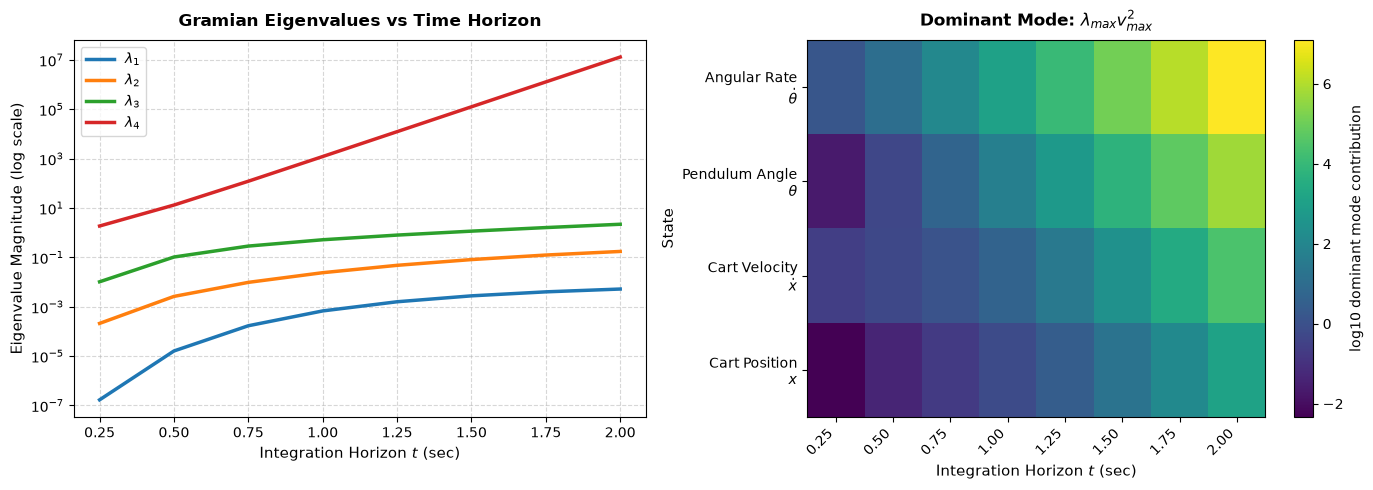

In [7]:
# part 2 - controllability gramian
def ctrb_gram_integrand(t):
    eAt = expm(A * t)
    return eAt @ B @ B.T @ eAt.T


tf = np.arange(0.25, 2.25, 0.25)
W_c_eigs_sweep = []
W_c_dominant_state_impact = []
for t in tf:
    W_c, _ = quad_vec(ctrb_gram_integrand, 0, t)
    W_c = 0.5 * (W_c + W_c.T)  # ensure W_c is symmetric
    W_c_eigs, W_c_vecs = np.linalg.eigh(W_c)
    W_c_eigs_sweep.append(W_c_eigs)
    W_c_dominant_state_impact.append(W_c_eigs[-1] * W_c_vecs[:, -1] ** 2)

W_c_eigs_sweep = np.array(W_c_eigs_sweep)
W_c_dominant_state_impact = np.array(W_c_dominant_state_impact)


def plot_gramian_modes(tf, eigs, state_impact):
    fig, (ax_eigs, ax_mode) = plt.subplots(1, 2, figsize=(14, 5))

    for i in range(eigs.shape[1]):
        ax_eigs.semilogy(tf, eigs[:, i], label=rf"$\lambda_{i + 1}$", linewidth=2.5)
    ax_eigs.set_title(
        "Gramian Eigenvalues vs Time Horizon", fontsize=12, fontweight="bold", pad=10
    )
    ax_eigs.set_xlabel(r"Integration Horizon $t$ (sec)", fontsize=11)
    ax_eigs.set_ylabel("Eigenvalue Magnitude (log scale)", fontsize=11)
    ax_eigs.grid(True, which="both", ls="--", alpha=0.5)
    ax_eigs.legend(loc="upper left", fontsize=10)

    log_impact = np.log10(state_impact.T)
    im = ax_mode.imshow(log_impact, aspect="auto", origin="lower", cmap="viridis")
    ax_mode.set_title(
        r"Dominant Mode: $\lambda_{max} v_{max}^2$",
        fontsize=12,
        fontweight="bold",
        pad=10,
    )
    ax_mode.set_xlabel(r"Integration Horizon $t$ (sec)", fontsize=11)
    ax_mode.set_ylabel("State", fontsize=11)
    ax_mode.set_xticks(np.arange(len(tf)))
    ax_mode.set_xticklabels([f"{t:.2f}" for t in tf], rotation=45, ha="right")
    ax_mode.set_yticks(np.arange(len(STATE_LABELS)))
    ax_mode.set_yticklabels(STATE_LABELS)
    fig.colorbar(im, ax=ax_mode, label="log10 dominant mode contribution")

    plt.tight_layout()
    plt.show()


plot_gramian_modes(tf, W_c_eigs_sweep, W_c_dominant_state_impact)

<a id="part-3-state-feedback-lmis"></a>
## Part 3 - State Feedback via LMIs

```mermaid
flowchart LR
    r["r"] --> sum(("Σ"))
    sum -->|"e"| K["K"]
    K -->|"u"| Plant["Plant"]
    Plant -->|"y"| branch(( ))
    branch --> out["output"]
    branch --> |"-"| sum

    classDef block fill:#ffffff,stroke:#111111,stroke-width:1.5px,color:#111111;
    classDef signal fill:#ffffff,stroke:#111111,stroke-width:1.3px,color:#111111;
    classDef junction fill:#ffffff,stroke:#111111,stroke-width:1.5px,color:#111111;

    class K,Plant block;
    class r,out signal;
    class sum,branch junction;
```

$$
\dot{z} = A z + B u \\
y = C z
$$

The control law is written using the positive sign convention, with negative feedback introduced through the tracking error $e$.

$$
u = K e \\
e = r - y
$$

where $K$ is the controller gain synthesized using one of the techniques below.

For the standard closed-loop feedback system without an observer, $C$ is often the identity matrix, so $y=z$. Setting $r=0$ gives

$$
\dot{z} = A z + B K e \to (A + B K) z
$$

so the closed-loop state-feedback matrix is

$$
\underline{A_{cl} = A + B K}
$$

Note Gymnasium exposes CartPole control as a discrete action space where $1$ moves the cart right and $0$ moves the cart left. With the default fixed actuator magnitude this is bang-bang control. The pure sign quantization policy is

$$
\alpha = \begin{cases}
1, & \text{if } Kz > 0, \\
0, & \text{if } Kz \le 0.
\end{cases}
$$

For the dynamic-compensator rollouts later in the notebook, I keep this binary sign interface but set Gymnasium's force magnitude from the controller output at each step. That avoids turning every small controller command into a full fixed-magnitude impulse.

### LMI State Feedback

Now for this control synthesis I am posing the problem in an LMI form suitable for my SDP solver.

A linear matrix inequality has the form

$$
F(z) = F_0 + \sum_{i=0}^{n} z_i F_i \succeq 0
$$

where $z\in\mathbb{R}^n$ is the optimization decision vector and each $F_i\in\mathbb{S}^n$ is a symmetric basis. The continuous-time state-feedback problem seeks a stabilizing controller such that

$$
(A + B K)^T P + P (A + B K) \prec 0 
$$

where $P\succ0$ is the Lyapunov matrix and the standard Lyapunov certificate is $A^{\mathsf T}P+PA\prec0$. This condition is bilinear in $P$ and $K$, so apply the standard change of variables

$$
Q = P^{-1}, \quad Y = KQ
$$

After applying a congruence transformation with $Q$, the inequality becomes

$$
Q (A + B K)^T + (A + B K) Q \prec 0, \quad Q \succ 0
$$

Using the substitution $Y=KQ$ reduces this to

$$
A Q + Q A^T + B Y + Y^T B^T \prec 0
$$

The static controller gain is recovered as

$$
K = Y Q^{-1}
$$

The merged decision vector is

$$
X = \begin{bmatrix} \operatorname{svec}(Q) \\ \operatorname{vec}(Y) \end{bmatrix}
$$

The convex problem has two LMI constraints. It can be posed as a feasibility problem or equipped with a linear or quadratic penalty on the merged decision vector $X$, with weights placed on the appropriate blocks. For a more thorough treatment of LMIs, see Boyd's [LMI book](https://stanford.edu/~boyd/lmibook/lmibook.pdf).

In [8]:
def solver_metric(result, name):
    return getattr(result, name, np.nan)


def print_solver_diagnostics(result):
    print("Akreon solver")
    print(f"  status: {result.status}")
    print(f"  event: {result.event}")
    print(f"  stalled: {result.stalled}")
    print(f"  iterations: {result.num_iter}")
    gap = solver_metric(result, "normalized_duality_gap")
    obj = solver_metric(result, "primal_objective_value")
    dual_obj = solver_metric(result, "dual_objective_value")
    primal = solver_metric(result, "primal_residual_norm")
    dual = solver_metric(result, "dual_residual_norm")
    equality = solver_metric(result, "equality_residual_norm")

    print(f"  mu: {gap:.3e}")
    print(f"  primal objective: {obj:.3e}")
    print(f"  dual objective: {dual_obj:.3e}")

    print("  residual norms:")
    print(f"    primal: {primal:.3e}")
    print(f"    dual: {dual:.3e}")
    print(f"    nu: {equality:.3e}")


config = SolverConfig()
# Use a 1e-3 complementarity gap for the feasibility solves.
config.duality_gap_tol = 1e-3

state_feedback_result = controls.solve_state_feedback(A, B, config)
K = np.asarray(state_feedback_result.K)

print_solver_diagnostics(state_feedback_result)
print(f"K = \n{K}")

Akreon solver
  status: OPTIMAL
  event: NONE
  stalled: False
  iterations: 8
  mu: 8.788e-04
  primal objective: 5.223e-03
  dual objective: -5.312e-03
  residual norms:
    primal: 1.000e-10
    dual: 1.000e-10
    nu: 0.000e+00
K = 
[[ 2.20405132  5.26146836 38.32718794  9.42135612]]


#### Closed-Loop Analysis

Verify that the closed-loop system is strictly stable, i.e., $\operatorname{Re}(\lambda)<0$.

Closed loop poles: [-8.86542815+0.j         -0.55552978+0.j         -2.08014297+2.10818442j
 -2.08014297-2.10818442j]
Closed loop stability: True


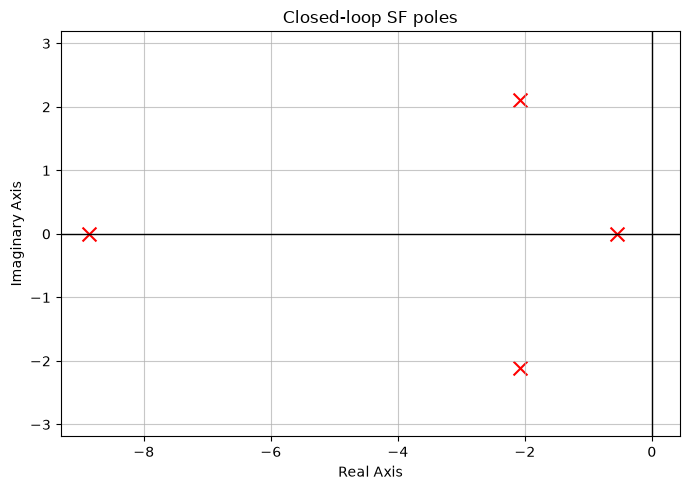

In [9]:
A_cl = A + B @ K

poles = np.linalg.eigvals(A_cl)
is_stable = np.all(np.real(poles) < 0.0)

print(f"Closed loop poles: {poles}")
print(f"Closed loop stability: {is_stable}")
plot_poles(poles, title="Closed-loop SF poles")

<a id="part-4-observer-feedback"></a>
## Part 4 - Observer Feedback

```mermaid
flowchart LR
    r["r"] --> sum(("Σ"))
    sum -->|"e"| K["K"]
    K -->|"u"| Plant["Plant"]
    Plant -->|"y"| out["output"]

    K -->|"u"| Obs["Observer / Estimator<br/>ẑ̇ = Aẑ + Bu + L(y − Cẑ)"]
    Plant -->|"y"| Obs
    Obs -->|"ẑ"| sum

    classDef block fill:#ffffff,stroke:#111111,stroke-width:1.5px,color:#111111;
    classDef signal fill:#ffffff,stroke:#444444,stroke-width:1.2px,color:#111111;
    classDef junction fill:#ffffff,stroke:#111111,stroke-width:1.5px,color:#111111;

    class K,Plant,Obs block;
    class r,out signal;
    class sum junction;
```

State feedback works directly when every state is available without measurement noise. In practice, the full state is rarely measured, so we estimate it from the available outputs before applying the feedback controllers derived above.

Assume that the cart position and pole angle (i.e., $x$ and $\theta$) are measured.

$$
y = C z,
\qquad
C = \begin{bmatrix}
1 & 0 & 0 & 0 \\
0 & 0 & 1 & 0
\end{bmatrix}.
$$

where $y$ is the output vector, and $C$ is the output matrix (linear map taking $z \to y$).

To produce a state estimate for feedback, design a Luenberger observer that reconstructs the full state from the measured output and the known applied input. Again setting $r = 0$, we have

$$
\dot{\hat{z}} = A \hat{z} + B u + L (y - C \hat{z})
$$

where the observer-based feedback controller now operates on $\hat{z}$.

$$
u = K \hat{z}
$$

The observer and state-feedback controller together form a dynamic compensator. Defining the estimation error as $e=z-\hat{z}$ gives the error dynamics

$$
e = z - \hat{z} \\
\dot{e} = (A - L C)e
$$

Therefore, the observer state-update equation can be rewritten as

$$
\underline{\dot{\hat{z}} = (A - L C)\hat{z} + B u + L y}
$$

#### Observability Matrix

Can the internal states of the dynamic system be reconstructed by observing its external outputs?

By the Cayley-Hamilton theorem, the observability matrix is the finite dual of the controllability matrix:

$$
\mathcal{O} = \begin{bmatrix}C \\ C A \\ C A^2 \\ \vdots \\ C A^{n-1} \end{bmatrix}.
$$

In [10]:
# part 1 - Cayley-Hamilton observability matrix
Obsv = ct.obsv(A, C)
print(f"Observability matrix = \n{Obsv}")

rank = np.linalg.matrix_rank(Obsv)
print(f"Observability rank: {rank}")

Observability matrix = 
[[ 1.    0.    0.    0.  ]
 [ 0.    0.    1.    0.  ]
 [ 0.    1.    0.    0.  ]
 [ 0.    0.    0.    1.  ]
 [ 0.    0.   -0.98  0.  ]
 [ 0.    0.   21.56  0.  ]
 [ 0.    0.    0.   -0.98]
 [ 0.    0.    0.   21.56]]
Observability rank: 4


#### Observability Gramian

The finite-horizon observability Gramian measures how much information about the internal state appears in the measured output over $0 \leq t \leq T$:

- $e^{At}$ describes how the system naturally evolves through the state dynamics.
- $C$ describes where and how strongly the state is measured through the output.
- $W_o(T)$ integrates the output sensitivity to the evolving state over the time horizon.

$$
W_o(T) = \int_{0}^{T} e^{A^{\mathsf T}t}C^{\mathsf T} C e^{At}\,dt.
$$

$W_o(T)$ identifies which state-space directions are easy or hard to infer from the measurements. Directions with large Gramian energy produce strong outputs, whereas directions with small Gramian energy are weakly visible and harder to estimate.

For an eigenpair $(\lambda_i,v_i)$ of $W_o(T)$, a large $\lambda_i$ means that the direction $v_i$ produces substantial measured-output energy; a small $\lambda_i$ means that direction leaves only a weak output trace.

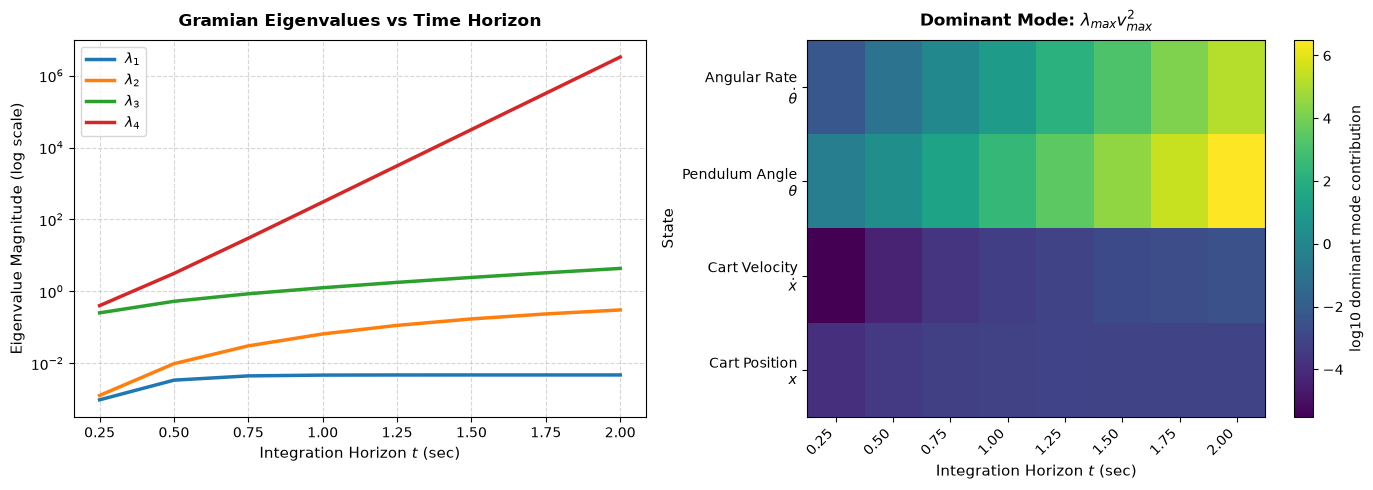

In [11]:
# part 2 - Observability Gramian
def obsv_gram_integrand(t):
    eAt = expm(A * t)
    return eAt.T @ C.T @ C @ eAt


tf = np.arange(0.25, 2.25, 0.25)
W_o_eigs_sweep = []
W_o_dominant_state_impact = []
for t in tf:
    W_o, _ = quad_vec(obsv_gram_integrand, 0, t)
    W_o = 0.5 * (W_o + W_o.T)  # ensure W_o is symmetric
    W_o_eigs, W_o_vecs = np.linalg.eigh(W_o)
    W_o_eigs_sweep.append(W_o_eigs)
    W_o_dominant_state_impact.append(W_o_eigs[-1] * W_o_vecs[:, -1] ** 2)

W_o_eigs_sweep = np.array(W_o_eigs_sweep)
W_o_dominant_state_impact = np.array(W_o_dominant_state_impact)

plot_gramian_modes(tf, W_o_eigs_sweep, W_o_dominant_state_impact)

### LMI Luenberger Observer

The observer synthesis is dual to the state feedback problem, instead of stabilizing the (A, B) pair with K, we seek to stabilize the estimation error dynamics $\dot{e} = (A - LC)e$ through the output pair (A, C).

The Lyapunov certificate for stability requires

$$
(A - LC)^T Q + Q(A - LC) \prec 0, \quad Q \succ 0.
$$

The condition above is also bilinear in $Q$ and $L$, so use the analogous change of variables

$$
W = -Q L
$$

and the observer synthesis LMI becomes

$$
A^T Q + Q A + W C + C^T W^T \prec 0, \quad Q \succ 0. 
$$

Therefore, the merged observer gain is recovered as

$$
L = -Q^{-1} W
$$

and the merged decision vector is

$$
X = \begin{bmatrix} \operatorname{svec}(Q) \\ \operatorname{vec}(W) \end{bmatrix}.
$$

In [12]:
state_observer_result = controls.solve_state_observer(A, C, config)
L = np.asarray(state_observer_result.L)

print_solver_diagnostics(state_observer_result)
print(f"L = \n{L}")

Akreon solver
  status: OPTIMAL
  event: NONE
  stalled: False
  iterations: 10
  mu: 4.499e-04
  primal objective: 2.455e-03
  dual objective: -2.944e-03
  residual norms:
    primal: 1.000e-10
    dual: 1.000e-10
    nu: 0.000e+00
L = 
[[ 1.78291973 -0.16066425]
 [ 1.22181737 -1.77155068]
 [-0.14071984 10.88198374]
 [-0.56858027 41.9216054 ]]


#### Observer Error Dynamics Analysis

$$
A_{obs} = A - L C
$$

As with the closed-loop matrix $A_{cl}$ above, verify that all observer poles lie strictly in the left half-plane (i.e., $\operatorname{Re}(\lambda) < 0$).

Closed loop poles: [-8.48219855+0.j         -0.89383285+0.63523021j -0.89383285-0.63523021j
 -2.39503922+0.j        ]
Closed loop stability: True


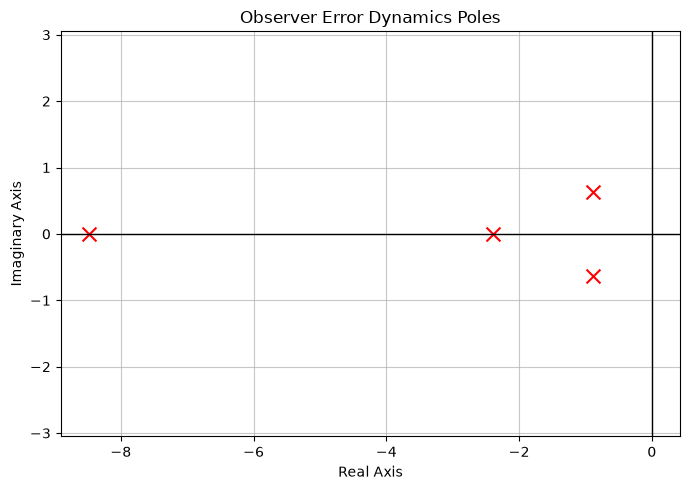

In [13]:
A_obs = A - L @ C

obs_poles = np.linalg.eigvals(A_obs)
is_obs_stable = np.all(np.real(obs_poles) < 0.0)

print(f"Closed loop poles: {obs_poles}")
print(f"Closed loop stability: {is_obs_stable}")
plot_poles(obs_poles, title="Observer Error Dynamics Poles")

#### Observer State Feedback

The observer-based state-feedback law can be cast as a dynamic compensator of the form

$$
\dot{\hat{z}} = (A + B K - L C)\hat{z} + L y \\
u = K \hat{z}
$$

Its state-space realization is

$$
K_{obs} = \begin{bmatrix} A + B K - L C & L \\ K & \underline{0} \end{bmatrix}
$$

Thus, the observer-based feedback law is a dynamic output-feedback compensator whose internal state is the estimate $\hat{z}$, whose input is the measurement $y$, and whose output is the control command $u$.

In [14]:
obs_ss = ct.ss(A + B @ K - L @ C, L, K, np.zeros((K.shape[0], C.shape[0])))
obs_ctrl = ct.c2d(obs_ss, CARTPOLE_DT)

print(f"Observer Controller \n{obs_ctrl}")

Observer Controller 
<StateSpace>: sys[1]$sampled
Inputs (2): ['u[0]', 'u[1]']
Outputs (1): ['y[0]']
States (4): ['x[0]', 'x[1]', 'x[2]', 'x[3]']
dt = 0.02

A = [[ 0.96513253  0.02059607  0.00916715  0.00177042]
     [ 0.01442758  1.09187255  0.57877864  0.17065018]
     [ 0.00183622 -0.00176328  0.78925189  0.01466988]
     [-0.06609932 -0.18389775 -1.49318499  0.65560731]]

B = [[ 0.0352643  -0.00220685]
     [ 0.02399066  0.10681682]
     [-0.00258382  0.20128411]
     [-0.01064467  0.51513692]]

C = [[ 2.20405132  5.26146836 38.32718794  9.42135612]]

D = [[0. 0.]]


<a id="part-5-optimal-control"></a>
## Part 5 - Optimal Control Design and Analysis

This section analyzes two approaches to optimal control: the Linear Quadratic Regulator (LQR) via the Continuous Algebraic Riccati Equation (CARE), and $H_2$ optimal control via linear matrix inequalities and semidefinite programming.

### LQR via CARE

LQR minimizes a cost function that penalizes state deviation and control effort, with $Q \succeq 0$ and $R \succ 0$.

$$
J = \frac{1}{2} \int_{0}^{\infty} (z^T Q z + u^T R u) dt.
$$

To find the optimal control law $u(t)$, introduce the value function $V(z(t))$, which represents the cost-to-go from the current time $t$ to infinity:

$$
V(z(t)) = \min_u \int_{t}^{\infty} (z^T Q z + u^T R u)\,d\tau.
$$

By the principle of optimality, split the minimized integral into the immediate cost and the cost of the remaining trajectory:

$$
V(z(t)) = \min_u [(z^T Q z + u^T R u)dt + V(z(t + dt))].
$$

Using a Taylor expansion, $V(z(t + dt))$ can be approximated as

$$
V(z(t + dt)) \approx V(z(t)) + \frac{\partial V}{\partial z}\dot{z}dt.
$$

Substituting this expansion into the variational equation gives the Hamilton-Jacobi-Bellman (HJB) equation:

$$
0 = \min_u[z^T Q z + u^T R u + \frac{\partial V}{\partial z}(A z + B u)].
$$

To determine the optimal control law $u(t)$, differentiate the minimized expression with respect to $u$ and set the result to zero:

$$
\frac{\partial}{\partial u}[z^T Q z + u^T R u + \frac{\partial V}{\partial z} B u] = 0 \\
2 R u + B^T(\frac{\partial V}{\partial z})^T = 0 \\
\underline{u^* = -R^{-1}B^T(\frac{\partial V}{\partial z})^T}.
$$

In LQR, the value function has a quadratic form, where $P \in \mathbb{S}^n_{++}$ is the Lyapunov matrix:

$$
\begin{align*}
V(z) = z^T P z \\
\frac{\partial V}{\partial z} = z^T P + z^T P^T \equiv 2 z^T P.
\end{align*}
$$

Substituting $u^*$ and $\frac{\partial V}{\partial z}$ into the HJB equation gives the continuous-time algebraic Riccati equation:

$$
0 = z^T Q z + (-R^{-1}B^T P z)^T R (-R^{-1} B^T P z) + 2z^T P (A z + B u) \\
0 = z^T(A^T P + P A - P B R^{-1} B^T P + Q) z \\
\underline{0 = A^T P + P A - P B R^{-1} B^T P + Q}
$$

Closed loop poles: [-8.79812861+0.j        -2.43804425+0.j        -0.80566116+0.5144447j
 -0.80566116-0.5144447j]
Closed loop stability: True


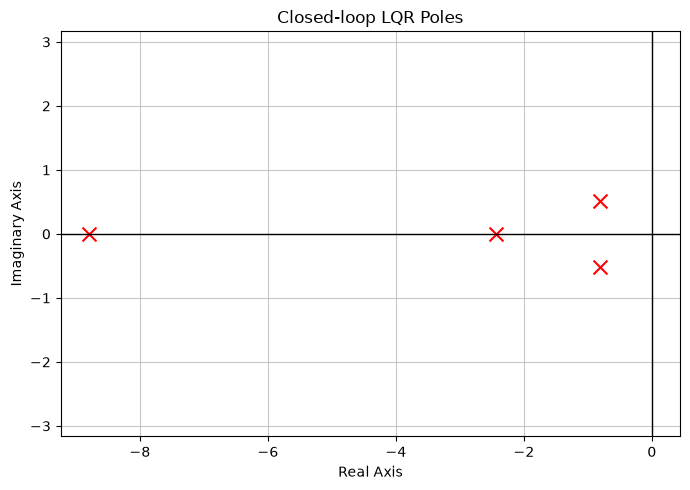

In [15]:
Q = np.eye(4, dtype=np.float64)
Q[2][2] *= 5.0
Q[3][3] *= 10.0
R = np.array([[1.0]])
K_lqr, _, _ = ct.lqr(A, B, Q, R)

A_cl_lqr = A - B @ K_lqr

poles_lqr = np.linalg.eigvals(A_cl_lqr)
is_lqr_stable = np.all(np.real(poles_lqr) < 0.0)

print(f"Closed loop poles: {poles_lqr}")
print(f"Closed loop stability: {is_lqr_stable}")
plot_poles(poles_lqr, title="Closed-loop LQR Poles")

#### Linear Quadratic Estimator (LQE)

LQE is the dual of LQR: it selects an observer gain that balances process and measurement noise to minimize state-estimation error. Here it is solved through the transposed LQR problem.

LQE poles: [-0.87034324+0.50302591j -0.87034324-0.50302591j -3.7207433 +0.j
 -5.85381454+0.j        ]
LQE stability: True


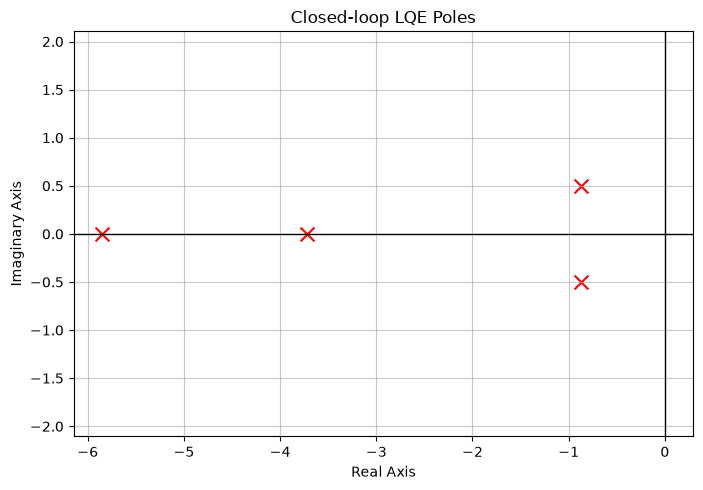

In [16]:
R_lqe = np.eye(2, dtype=np.float64)

K_dual, _, _ = ct.lqr(A.T, C.T, Q, R_lqe)

L_lqe = K_dual.T
A_cl_lqe = A - L_lqe @ C

poles_lqe = np.linalg.eigvals(A_cl_lqe)
is_lqe_stable = np.all(np.real(poles_lqe) < 0.0)

print(f"LQE poles: {poles_lqe}")
print(f"LQE stability: {is_lqe_stable}")
plot_poles(poles_lqe, title="Closed-loop LQE Poles")

#### Linear Quadratic Gaussian (LQG)

Dynamic compensator for the LQR + LQE closed-loop system.

In [17]:
lqg_ss = ct.ss(
    A - B @ K_lqr - L_lqe @ C, L_lqe, K_lqr, np.zeros((K.shape[0], C.shape[0]))
)
lqg_ctrl = ct.c2d(lqg_ss, CARTPOLE_DT)

print(f"LQG Controller \n{lqg_ctrl}")

LQG Controller 
<StateSpace>: sys[3]$sampled
Inputs (2): ['u[0]', 'u[1]']
Outputs (1): ['y[0]']
States (4): ['x[0]', 'x[1]', 'x[2]', 'x[3]']
dt = 0.02

A = [[ 9.65637182e-01  2.00676146e-02  1.05624499e-02  1.45914907e-03]
     [-6.60117521e-04  1.04017005e+00  4.89334818e-01  1.38327892e-01]
     [ 5.13948426e-03 -7.32335816e-04  8.12274347e-01  1.55062747e-02]
     [-1.34377593e-02 -8.03784144e-02 -1.33982498e+00  7.19960854e-01]]

B = [[ 0.0345435  -0.00485096]
     [ 0.01822651  0.07500977]
     [-0.0054832   0.18054918]
     [-0.0216484   0.60409861]]

C = [[ -1.          -2.28725542 -31.51453309  -7.5673753 ]]

D = [[0. 0.]]


### $H_2$ Control via LMIs and SDP

```mermaid
flowchart LR
    r["r"] --> sum(("Σ"))
    sum -->|"e"| K["K"]
    K -->|"u"| Plant["Plant"]

    w["w"] --> Plant

    Plant -->|"z_p"| branch(( ))
    branch --> out["performance"]
    branch --> |"-"| sum

    classDef block fill:#ffffff,stroke:#111111,stroke-width:1.5px,color:#111111;
    classDef signal fill:#ffffff,stroke:#111111,stroke-width:1.3px,color:#111111;
    classDef junction fill:#ffffff,stroke:#111111,stroke-width:1.5px,color:#111111;

    class K,Plant block;
    class r,w,out signal;
    class sum,branch junction;
```

LQR is fantastic when we understand the model well and can tune $Q$ and $R$ to our desired target linear responses. However, rarely is the model known perfectly, and famously LQG does not guarantee robustness -- Doyle's `Guaranteed Margins for LQG Regulators` abstract says "There are none".

To make the closed-loop system reject disturbances while minimizing output energy, begin with a linear state-space model whose disturbance enters the plant:

$$
\dot{z} = A z + B_w w \\
z_p = C_z z
$$

where $w$ is the disturbance input and $z_p$ is the performance output, (i.e., the part of the state/output behavior we care about keeping small).

So, how does $w$ impact the plant? We can use the controllability Gramian again to measure how disturbance energy spreads through the states in the closed-loop dynamics.

$$
A W_c + W_c A^T + B_w B_w^T = 0
$$

The H2 metric then measures how much of this disturbance-driven state energy is visible through the performance output

$$
\|T_{w \to z_p}\|_2^2
=
\operatorname{Tr}\!\left(C_z W_c C_z^T\right)
$$

The above is stating the portion of the state energy that is visible at the performance output as a total scalar output energy across all state channels. Basically, minimizing the above H2 metric means minimizing the effect of disturbances across the state channels as seen by the performance output.

Let's now introduce a control input along with the disturbance channel and re-write the linear state-space model

$$
\dot{z} = A z + B_w w + B_u u \\
z_p = C_z z + D_{u \to z}u \\
u = K z
$$

The closed-loop system takes a similar form as the state feedback case

$$
A_{cl} = A + B_u K \\
C_{cl} = C_z + D_{u \to z} K
$$

The $H_2$ optimization problem is

$$
\begin{aligned}
    \underset{K,\,W_c}{\text{minimize}} \quad
    & \operatorname{Tr}\!\left(C_{cl} W_c C_{cl}^T\right) \\[4pt]
    \text{subject to} \quad
    & A_{cl} W_c + W_c A_{cl}^T + B_w B_w^T \prec 0 \\[4pt]
    & W_c \succ 0
\end{aligned}
$$

where the first LMI constraint states that the closed-loop dynamics dissipate covariance/energy faster than the disturbance ($B_w$) injects it.

The H2 controller chooses $K$ to minimize the total closed-loop impulse-response energy as described by the transfer function from $T_{w \to z_p}$.

$$
\min_K \left\|T_{w \to z_p}(K)\right\|_2^2.
$$

The problem above is bilinear in $K W_c$, so let

$$
Y = K W_c
$$

and the input-to-state Gramian inequality can be written as

$$
\begin{align*}
    A_{cl} W_c + W_c A_{cl}^T + B_w B_w^T
    &=
    A W_c + W_c A^T + B_u Y + Y^T B_u^T + B_w B_w^T \prec 0
\end{align*}
$$

Therefore, the first convex LMI constraint is

$$
\underline{
A W_c + W_c A^T + B_u Y + Y^T B_u^T + B_w B_w^T \prec 0
}
$$

and the objective can be rewritten as

$$
\begin{align*}
    C_{cl} W_c C_{cl}^T
    &=
    (C_z + D_{u \to z} K) W_c (C_z + D_{u \to z} K)^T \\[4pt]
    &=
    (C_z W_c + D_{u \to z}Y) W_c^{-1}
    (C_z W_c + D_{u \to z}Y)^T
\end{align*}
$$

where the objective is transformed with an epigraph lift introducing the auxiliary variable $\bar{Z}$

$$
\underline{
\bar{Z}
\succeq
(C_z W_c + D_{u \to z}Y)
W_c^{-1}
(C_z W_c + D_{u \to z}Y)^T
}
$$

The above can be cast as an LMI using the Schur complement, and we arrive at the following convex problem for H2 feedback control

$$
\begin{aligned}
    \underset{W_c,\,Y,\,\bar{Z}}{\text{minimize}} \quad
    & \operatorname{Tr}\!\left(\bar{Z}\right) \\[4pt]
    \text{subject to} \quad
    &
    A W_c + W_c A^T + B_u Y + Y^T B_u^T + B_w B_w^T \prec 0 \\[6pt]
    &
    \begin{bmatrix}
        \bar{Z} & C_z W_c + D_{u \to z} Y \\
        \left(C_z W_c + D_{u \to z} Y\right)^T & W_c
    \end{bmatrix} \succeq 0 \\[10pt]
    & W_c \succ 0,\qquad \bar{Z} \succeq 0
\end{aligned}
$$

The controller gain is then recovered as

$$
K = Y W_c^{-1}
$$

#### Disturbance Dynamics

Let the disturbance $w$ be an exogenous input that enters through the same physical force channel as the actuator, so the total lateral force is

$$
F_{tot} = F_w + F_u
$$

This gives the generalized H2 feedback plant

$$
\dot{z} = A z + B_w w + B_u u \equiv A z + \begin{bmatrix}B_w & B_u\end{bmatrix} \begin{bmatrix} w \\ u \end{bmatrix}
$$

For the cartpole we have $B_w = B_u = B$, so

$$
B_{tot} = \begin{bmatrix}B_w & B_u\end{bmatrix} = \begin{bmatrix} B & B \end{bmatrix}
$$

Now express the $H_2$ objective using the LQR weighting pattern, whose cost captures state-deviation energy and control effort.

$$
z_p = \begin{bmatrix}Q^{1/2}z \\ R^{1/2}u\end{bmatrix} = \begin{bmatrix}Q^{1/2} & 0 \\ 0 & R^{1/2}\end{bmatrix}\begin{bmatrix}z \\ u \end{bmatrix}
$$

Equivalently, in generalized plant form with inputs $\begin{bmatrix}w & u \end{bmatrix}$

$$
z_p = C_z z + D_{w \to z} w + D_{u \to z} u
$$

where

$$
C_z = \begin{bmatrix}Q^{1/2} \\ 0\end{bmatrix}, \quad D_{w \to z} = 0, \quad D_{u \to z} = \begin{bmatrix} 0 \\ R^{1/2} \end{bmatrix}.
$$

The energy cost can be written similar to $J$ from LQR,
$$
z_p^T z_p = z^T Q z + u^T R u
$$

where the performance output is augmented to include both weighted state deviation and weighted control effort:

$$
z_p \in \mathbb{R}^5, \quad z_p = \begin{bmatrix}z_{p,x} \\ z_{p,u}\end{bmatrix} = \begin{bmatrix}Q^{1/2}z \\ R^{1/2}u\end{bmatrix}.
$$

The $z_p$ vector can be described as $z_{p,x} \in \mathbb{R}^4$ and $z_{p,u}\in \mathbb{R}^1$,

$$
\begin{aligned}
n_z &= 4 &&\text{plant state dimension}, \\
n_w &= 1 &&\text{exogenous disturbance dimension}, \\
n_u &= 1 &&\text{control input dimension}, \\
n_{z_p} &= n_z+n_u = 5 &&\text{performance-output dimension}.
\end{aligned}
$$

Therefore, $C_z \in \mathbb{R}^{5 \times 4}$, $D_{w \to z} \in \mathbb{R}^{5 \times 1}$, and $D_{u \to z} \in \mathbb{R}^{5 \times 1}$. With native input ordering $\begin{bmatrix}w & u\end{bmatrix}^{\mathsf T}$, the combined feedthrough matrix is

$$
D_z = \begin{bmatrix}D_{w \to z} & D_{u \to z}\end{bmatrix} \in \mathbb{R}^{5 \times 2}
$$

The implementation below reuses $Q$ and $R$ and is scaled down to improve numerical conditioning for the solver.

In [18]:
config = SolverConfig()
config.primal_feas_tol = 1e-3
config.dual_feas_tol = 1e-3
config.duality_gap_tol = 1e-3

B_tot = np.column_stack((B, B))  # [ B_w, B_u ]

# Scaling to preserve Q:R tradeoff and improves solver conditioning
cost_scale = 0.5
Q_h2 = cost_scale * Q
R_h2 = cost_scale * R

# Performance factors satisfy C_z^T C_z = Q_h2 and D_zu^T D_zu = R_h2
Q_sqrt = np.linalg.cholesky(Q_h2).T
R_sqrt = np.linalg.cholesky(R_h2).T
C_z = np.vstack((Q_sqrt, np.zeros((1, A.shape[0]))))
D_zw = np.zeros((C_z.shape[0], B.shape[1]), dtype=np.float64)
D_zu = np.vstack((np.zeros((Q.shape[0], B.shape[1])), R_sqrt))
D_z = np.hstack((D_zw, D_zu))

h2_feedback_result = controls.solve_h2_state_feedback(A, B_tot, C_z, D_z, exogenous_dim=1, config=config)

print_solver_diagnostics(h2_feedback_result)
K_h2 = np.asarray(h2_feedback_result.K)
print(f"K=\n{K_h2}")

Akreon solver
  status: OPTIMAL
  event: NONE
  stalled: False
  iterations: 38
  mu: 4.575e-04
  primal objective: 6.428e+00
  dual objective: 6.422e+00
  residual norms:
    primal: 1.000e-10
    dual: 1.000e-10
    nu: 0.000e+00
K=
[[ 1.00168945  2.28772338 31.51686164  7.57705512]]


H2 CL poles: [-8.82915786+0.j         -2.4249413 +0.j         -0.80614385+0.51684685j
 -0.80614385-0.51684685j]
H2 CL stable: True


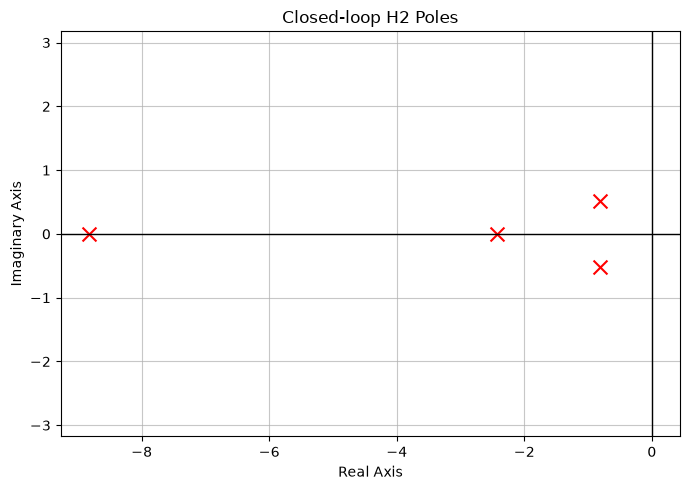

In [19]:
A_h2_cl = A + B @ K_h2
h2_poles = np.linalg.eigvals(A_h2_cl)

print(f"H2 CL poles: {h2_poles}")
print(f"H2 CL stable: {np.all(np.real(h2_poles) < 0.0)}")
plot_poles(h2_poles, title="Closed-loop H2 Poles")

#### H2 Observer Synthesis

The H2 observer uses the same plant state

$$
z\in\mathbb{R}^{4},
\qquad
z = \begin{bmatrix}x & \dot{x} & \theta & \dot{\theta}\end{bmatrix}^{T},
$$

but its generalized plant has a different input/output layout than the feedback problem. The observer disturbance vector includes the force disturbance plus independent measurement-noise channels on cart position and pendulum angle:

$$
w_o = \begin{bmatrix}w_f & v_x & v_\theta\end{bmatrix}^{T} \in \mathbb{R}^{3}.
$$

The force disturbance enters the state dynamics, while the two sensor-noise channels enter only through the measured output:

$$
\dot{z} = A z + \begin{bmatrix}B_w & 0 & 0\end{bmatrix}w_o,
$$

$$
y = C_y z + D_{w \to y}w_o, 
\qquad D_{w \to y}=\begin{bmatrix}
    0 & \sigma_x & 0 \\ 
    0 & 0 & \sigma_\theta
\end{bmatrix}.
$$

We'll reuse the same observer sensing measurement map from above so,

$$
y\in\mathbb{R}^{2},
\qquad
y=\begin{bmatrix}x & \theta\end{bmatrix}^{T},
\qquad
C_y=
\begin{bmatrix}
1 & 0 & 0 & 0 \\
0 & 0 & 1 & 0
\end{bmatrix}.
$$

The observer performance output is tied to weighted estimation error:

$$
z_e = Q_e^{1/2}e,
\qquad
e=z-\hat{z},
\qquad
z_e\in\mathbb{R}^{4}.
$$

The native $H_2$ observer synthesis expects the generalized output ordering $\begin{bmatrix}z_e & y\end{bmatrix}^{\mathsf T}$. The matrix supplied to the solver is the corresponding plant-side output map:

$$
\begin{bmatrix}
z_e \\
y
\end{bmatrix}
=
\underbrace{
\begin{bmatrix}
Q_e^{1/2} \\
C_y
\end{bmatrix}}_{C_{obs}}
z
+
\underbrace{
\begin{bmatrix}
0 \\
D_{w \to y}
\end{bmatrix}}_{D_{obs}}
w_o,
$$

The observer dimensions in this notebook are

$$
\begin{aligned}
n_z &= 4 &&\text{plant state dimension}, \\
n_{w_o} &= 3 &&\text{observer disturbance/noise dimension}, \\
n_{z_e} &= 4 &&\text{performance output estimation error dimension}, \\
n_y &= 2 &&\text{measurement-output dimension}, \\
n_{[z_e,y]} &= n_{z_e}+n_y = 6 &&\text{stacked generalized-output dimension}.
\end{aligned}
$$

where $B_{w,obs} \in \mathbb{R}^{4\times 3}$, $C_{obs}\in\mathbb{R}^{6\times4}$, and $D_{obs}\in\mathbb{R}^{6\times3}$. 

Akreon solver
  status: OPTIMAL
  event: NONE
  stalled: False
  iterations: 23
  mu: 7.060e-04
  primal objective: 1.492e+01
  dual objective: 1.491e+01
  residual norms:
    primal: 1.000e-10
    dual: 1.000e-10
    nu: 0.000e+00
L=
[[ 3.97753302 -1.07664105]
 [ 8.48194843 -6.37697636]
 [-1.04188571  9.90470271]
 [-8.17235463 49.78357704]]
H2 observer poles: [-1.99576985+1.67997273j -1.99576985-1.67997273j -4.94534801+2.05890555j
 -4.94534801-2.05890555j]


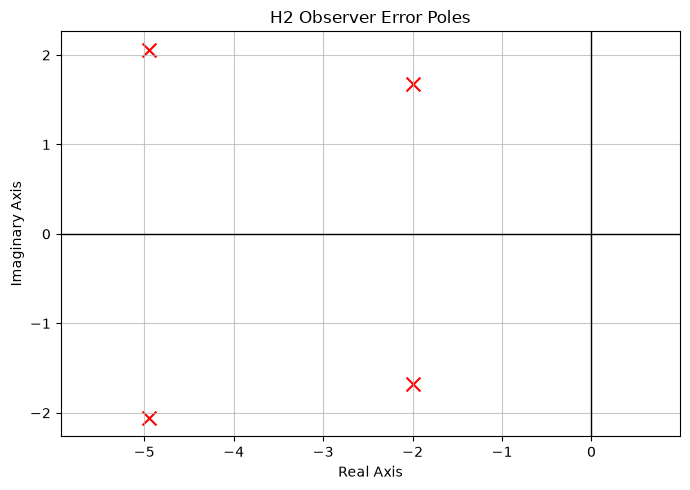

In [20]:
B_w_obs = np.column_stack((B, np.zeros((A.shape[0], C.shape[0]))))
C_obs_h2 = np.vstack((Q_sqrt, C))

sensor_noise_scale = 0.1
D_obs_h2 = np.zeros((C_obs_h2.shape[0], B_w_obs.shape[1]), dtype=np.float64)
D_obs_h2[Q_sqrt.shape[0] :, 1:] = sensor_noise_scale * np.eye(C.shape[0])

observer_result = controls.solve_h2_state_observer(
    A, B_w_obs, C_obs_h2, D_obs_h2, performance_dim=4, config=config
)
print_solver_diagnostics(observer_result)
L_h2 = np.asarray(observer_result.L)
print(f"L=\n{L_h2}")

observer_poles_h2 = np.linalg.eigvals(A - L_h2 @ C)
print(f"H2 observer poles: {observer_poles_h2}")
plot_poles(observer_poles_h2, title="H2 Observer Error Poles")

#### H2 Dynamic Compensator

The H2 feedback gain and H2 observer are packed into a dynamic compensator. The compensator is an LTI system whose input is the plant measurement $y$ and whose output is the actuator command $u$:

$$
\dot{\hat{z}}
=A\hat{z}+B_u u+L_{h2}\left(y-C_y\hat{z}\right),
\qquad
u=K_{h2}\hat{z}.
$$

Here $y-C_y\hat{z}$ is the measurement innovation. For the nominal measurement $y=C_yz$, it is

$$
y-C_y\hat{z}=C_y(z-\hat{z}).
$$

Thus $C_y$ maps the state-estimation error into measurement coordinates, and $L_{h2}$ maps that measurement error back into the observer-state correction.

Substituting the feedback law into the observer gives the standalone compensator realization

$$
\dot{\hat{z}}
=\left(A+B_uK_{h2}-L_{h2}C_y\right)\hat{z}+L_{h2}y,
\qquad
u=K_{h2}\hat{z}.
$$

Its state-space realization is therefore

$$
K_{h2}(s)=
\left[
\begin{array}{c|c}
A+B_uK_{h2}-L_{h2}C_y & L_{h2} \\
\hline
K_{h2} & 0
\end{array}
\right],
$$

with input $y$ and output $u$. 

#### Plant + K(s)

To see the closed-loop behavior, the compensator must be placed in the feedback role around the plant. With the nominal plant

$$
\dot{z}=Az+B_u u,
\qquad
y=C_yz,
$$

and the compensator feeding through $u=K_{h2}\hat{z}$, first expand the observer correction using the plant measurement:

$$
\begin{aligned}
\dot{\hat{z}}
&=(A+B_uK_{h2})\hat{z}+L_{h2}(y-C_y\hat{z}) \\
&=(A+B_uK_{h2})\hat{z}+L_{h2}C_y(z-\hat{z}) \\
&=L_{h2}C_yz+(A+B_uK_{h2}-L_{h2}C_y)\hat{z}.
\end{aligned}
$$

The $L_{h2}C_y$ lower-left block therefore comes from the part of the innovation driven by the true plant state $z$. The matching $-L_{h2}C_y$ term appears in the lower-right block because the predicted measurement $C_y\hat{z}$ is subtracted.

Using the augmented plant-plus-compensator state $\begin{bmatrix}z & \hat{z}\end{bmatrix}^{T}$, the closed-loop dynamics are

$$
\begin{bmatrix}
\dot{z} \\
\dot{\hat{z}}
\end{bmatrix}
=
\underbrace{
\begin{bmatrix}
A & B_uK_{h2} \\
L_{h2}C_y & A+B_uK_{h2}-L_{h2}C_y
\end{bmatrix}}_{A_{aug}}
\begin{bmatrix}
z \\
\hat{z}
\end{bmatrix}.
$$

Below shows the standalone compensator pole plot checks the controller realization; the augmented pole plot checks the actual nominal plant with that compensator in the loop. 

H2 compensator poles: [-11.62720683+9.72170427j -11.62720683-9.72170427j
  -1.74710447+1.2707058j   -1.74710447-1.2707058j ]
H2 nominal plant + compensator stable: True
H2 nominal plant + compensator poles: [-8.82915786+0.j         -4.94534801+2.05890555j -4.94534801-2.05890555j
 -1.99576985+1.67997273j -1.99576985-1.67997273j -2.4249413 +0.j
 -0.80614385+0.51684685j -0.80614385-0.51684685j]
H2 observer controller 
<StateSpace>: sys[5]$sampled
Inputs (2): ['u[0]', 'u[1]']
Outputs (1): ['y[0]']
States (4): ['x[0]', 'x[1]', 'x[2]', 'x[3]']
dt = 0.02

A = [[ 9.22398837e-01  1.96201663e-02  2.46437291e-02  1.57204237e-03]
     [-1.31940677e-01  1.03876171e+00  5.60109164e-01  1.39101246e-01]
     [ 1.90876919e-02 -5.85424521e-04  8.05942726e-01  1.54513074e-02]
     [ 9.14998968e-02 -7.91886586e-02 -1.43678022e+00  7.18758834e-01]]

B = [[ 0.07777751 -0.01905711]
     [ 0.1495148   0.00372907]
     [-0.01943021  0.18692639]
     [-0.1266174   0.70162999]]

C = [[ 1.00168945  2.28772338 31.

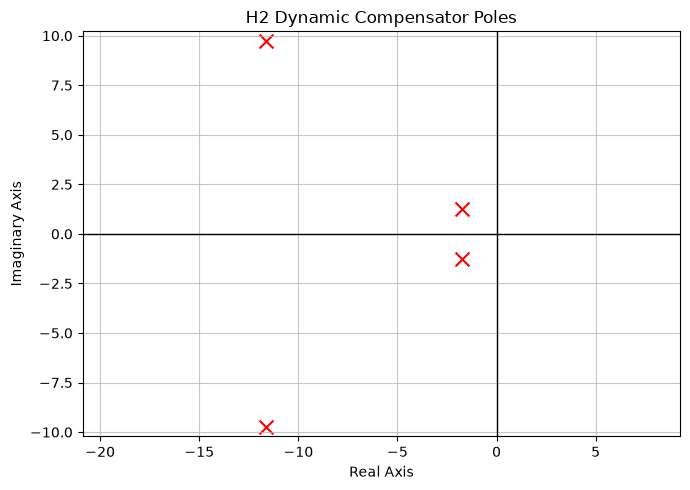

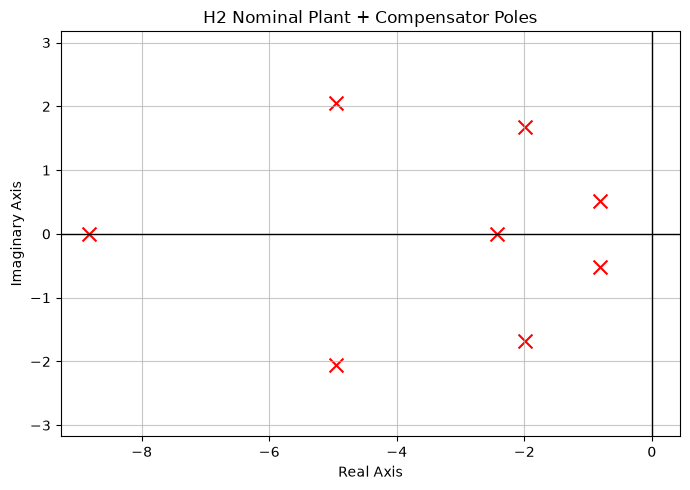

In [21]:
h2_compensator_ss = ct.ss(
    A + B @ K_h2 - L_h2 @ C,
    L_h2,
    K_h2,
    np.zeros((K_h2.shape[0], C.shape[0])),
)
h2_compensator_poles = ct.poles(h2_compensator_ss)
h2_obs_ctrl = ct.c2d(h2_compensator_ss, CARTPOLE_DT)

A_h2_augmented = np.block(
    [
        [A, B @ K_h2],
        [L_h2 @ C, A + B @ K_h2 - L_h2 @ C],
    ]
)
h2_augmented_poles = np.linalg.eigvals(A_h2_augmented)

print(f"H2 compensator poles: {h2_compensator_poles}")
print(
    "H2 nominal plant + compensator stable: "
    f"{np.all(np.real(h2_augmented_poles) < 0.0)}"
)
print(f"H2 nominal plant + compensator poles: {h2_augmented_poles}")
print(f"H2 observer controller \n{h2_obs_ctrl}")

display(plot_poles(h2_compensator_poles, title="H2 Dynamic Compensator Poles"))
display(plot_poles(h2_augmented_poles, title="H2 Nominal Plant + Compensator Poles"))

<a id="part-6-uncertainty-modeling"></a>
## Part 6 - Uncertainty Modeling with Polytopic LMIs

The nominal H2 controller and observer above use one fixed pendulum mass. Let the pendulum mass vary by $\pm 15\%$:

$$
\hat{m}_p\in[0.85m_{p},\,1.15m_{p}].
$$

For this linearized model, $A(m_p)$ is affine in $m_p$, while $B$, $C$, and the H2 performance channels remain fixed. The endpoint plants therefore define the full interval exactly:

$$
A(\alpha)=\alpha A_{\mathrm{light}}+(1-\alpha)A_{\mathrm{heavy}},
\qquad
0\leq\alpha\leq1.
$$

For the polytopic LMI, use the $H_2$ feedback and observer synthesis to obtain $K_{h2,p}$ and $L_{h2,p}$ over the plants generated by the convex combination above. This gives a fixed robust controller and observer over the modeled polytope.

Polytopic H2 feedback
Akreon solver
  status: OPTIMAL
  event: NONE
  stalled: False
  iterations: 20
  mu: 6.904e-04
  primal objective: 6.461e+00
  dual objective: 6.443e+00
  residual norms:
    primal: 1.000e-10
    dual: 1.000e-10
    nu: 0.000e+00
K_h2_poly=
[[ 0.98911486  2.28678935 31.83290338  7.59758006]]

Polytopic H2 Observer
Akreon solver
  status: OPTIMAL
  event: NONE
  stalled: False
  iterations: 15
  mu: 4.556e-04
  primal objective: 1.513e+01
  dual objective: 1.512e+01
  residual norms:
    primal: 1.000e-10
    dual: 1.000e-10
    nu: 0.000e+00
L_h2_poly=
[[ 3.96597636 -1.06836451]
 [ 8.53882067 -6.55799945]
 [-1.07763013  9.94762306]
 [-8.35992685 50.23360596]]

m_p vertex 0: 0.0850 kg
  feedback poles: [-8.71940212+0.j         -2.67203968+0.j         -0.75846448+0.50678118j
 -0.75846448-0.50678118j]
  obeserver poles: [-1.99631774+1.67234305j -1.99631774-1.67234305j -4.96048198+2.19270905j
 -4.96048198-2.19270905j]

m_p vertex 1: 0.1150 kg
  feedback poles: [-8.8

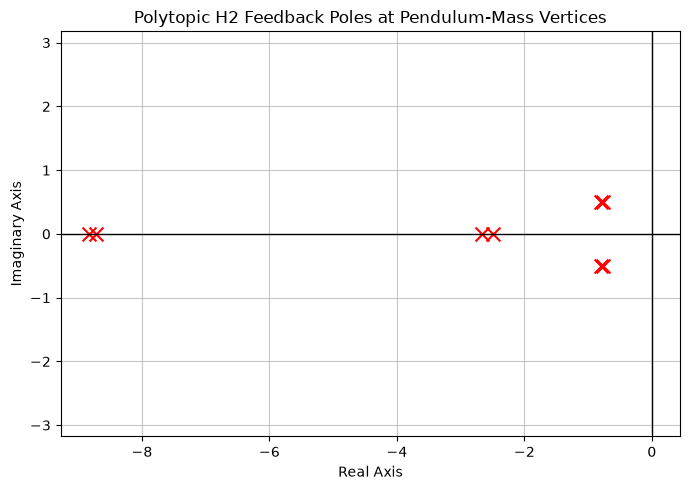

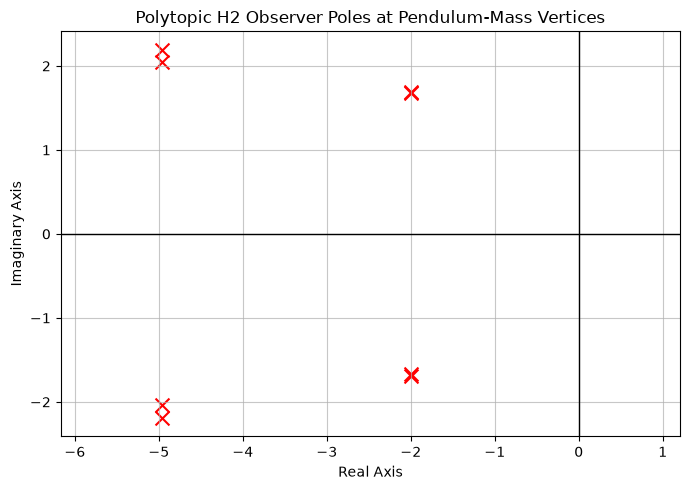

In [22]:
mp_uncertainty = 0.15
mp_vertices = mp * np.array([1.0 - mp_uncertainty, 1.0 + mp_uncertainty])


def cartpole_A_mp(mp_hat):
    return np.array(
        [
            [0.0, 1.0, 0.0, 0.0],
            [0.0, 0.0, -(mp_hat / mc) * gravity, 0.0],
            [0.0, 0.0, 0.0, 1.0],
            [
                0.0,
                0.0,
                ((mp_hat + mc) / (mc * pole_length)) * gravity,
                0.0,
            ],
        ],
        dtype=np.float64,
    )


A_mass_vertices = np.stack([cartpole_A_mp(mass) for mass in mp_vertices])
vertex_count = A_mass_vertices.shape[0]


def repeat_at_vertices(matrix):
    return np.repeat(matrix[np.newaxis, :, :], vertex_count, axis=0)


poly_config = SolverConfig()
poly_config.primal_feas_tol = 1e-3
poly_config.dual_feas_tol = 5e-3
poly_config.duality_gap_tol = 1e-3

poly_feedback_result = controls.solve_h2_polytopic_state_feedback(
    A_mass_vertices,
    repeat_at_vertices(B_tot),
    repeat_at_vertices(C_z),
    repeat_at_vertices(D_z),
    exogenous_dim=1, config=poly_config,
)

print("Polytopic H2 feedback")
print_solver_diagnostics(poly_feedback_result)
K_h2_poly = np.asarray(poly_feedback_result.K)
print(f"K_h2_poly=\n{K_h2_poly}")

poly_observer_result = controls.solve_h2_polytopic_state_observer(
    A_mass_vertices,
    repeat_at_vertices(B_w_obs),
    repeat_at_vertices(C_obs_h2),
    repeat_at_vertices(D_obs_h2),
    performance_dim=4, config=poly_config,
)
print("\nPolytopic H2 Observer")
print_solver_diagnostics(poly_observer_result)
L_h2_poly = np.asarray(poly_observer_result.L)
print(f"L_h2_poly=\n{L_h2_poly}")

poly_feedback_poles = [
    np.linalg.eigvals(A_vertex + B @ K_h2_poly) for A_vertex in A_mass_vertices
]

poly_observer_poles = [
    np.linalg.eigvals(A_vertex - L_h2_poly @ C) for A_vertex in A_mass_vertices
]

for index, mass in enumerate(mp_vertices):
    print(f"\nm_p vertex {index}: {mass:.4f} kg")
    print(f"  feedback poles: {poly_feedback_poles[index]}")
    print(f"  obeserver poles: {poly_observer_poles[index]}")

display(
    plot_poles(
        np.concatenate(poly_feedback_poles),
        title="Polytopic H2 Feedback Poles at Pendulum-Mass Vertices",
    )
)

display(
    plot_poles(
        np.concatenate(poly_observer_poles),
        title="Polytopic H2 Observer Poles at Pendulum-Mass Vertices",
    )
)


The dynamic compensator for the polytopic synthesis has the same form as the nominal $H_2$ compensator.

$$
K_{h2,p}(s)=
\left[\begin{array}{c|c}
A_0+B K_{h2,p}-L_{h2,p}C & L_{h2,p}\\
\hline
K_{h2,p} & 0
\end{array}\right].
$$

As above, plot the poles of both the compensator and the full augmented plant with the compensator in the loop.

m_p vertex 0 plant + compensator stable: True
m_p vertex 1 plant + compensator stable: True

Polytopic H2 compensator poles: [-11.67404862+9.78484501j -11.67404862-9.78484501j
  -1.73693647+1.28057805j  -1.73693647-1.28057805j]
Polytopic H2 compensator:
<StateSpace>: sys[7]$sampled
Inputs (2): ['u[0]', 'u[1]']
Outputs (1): ['y[0]']
States (4): ['x[0]', 'x[1]', 'x[2]', 'x[3]']
dt = 0.02

A = [[ 9.22608370e-01  1.96221167e-02  2.45721951e-02  1.57451126e-03]
     [-1.32696749e-01  1.03871707e+00  5.67266404e-01  1.39479436e-01]
     [ 1.97342126e-02 -5.77846504e-04  8.05085806e-01  1.54375076e-02]
     [ 9.42773014e-02 -7.90854398e-02 -1.45250455e+00  7.17989937e-01]]

B = [[ 0.07756575 -0.01893022]
     [ 0.15004216  0.00194056]
     [-0.02007219  0.18768088]
     [-0.12893748  0.70663331]]

C = [[ 0.98911486  2.28678935 31.83290338  7.59758006]]

D = [[0. 0.]]


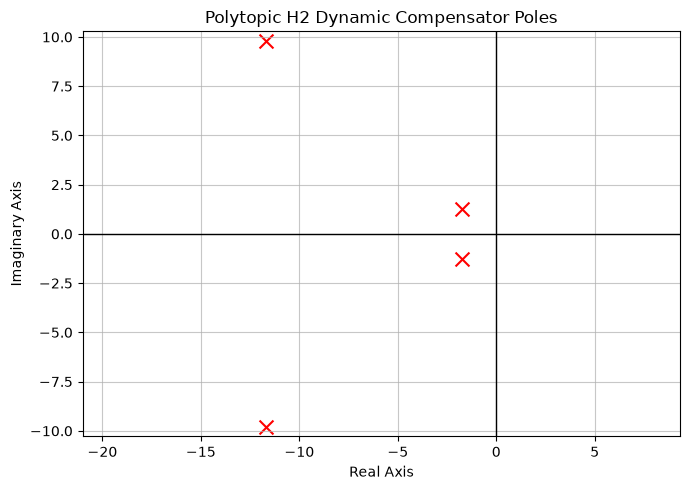

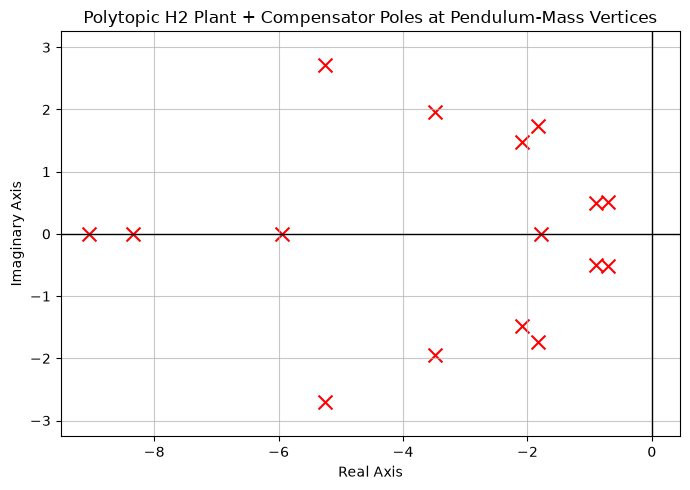

In [23]:
A_h2_poly_compensator = A + B @ K_h2_poly - L_h2_poly @ C
h2_poly_compensator = ct.ss(
    A_h2_poly_compensator,
    L_h2_poly,
    K_h2_poly,
    np.zeros((K_h2_poly.shape[0], C.shape[0])),
)
h2_poly_compensator_poles = ct.poles(h2_poly_compensator)
h2_poly_compensator_discrete = ct.c2d(h2_poly_compensator, CARTPOLE_DT)

poly_augmented_poles = []
for index, A_vertex in enumerate(A_mass_vertices):
    A_augmented = np.block(
        [
            [A_vertex, B @ K_h2_poly],
            [L_h2_poly @ C, A_h2_poly_compensator],
        ]
    )
    vertex_augmented_poles = np.linalg.eigvals(A_augmented)
    poly_augmented_poles.append(vertex_augmented_poles)
    print(
        f"m_p vertex {index} plant + compensator stable: "
        f"{np.all(np.real(vertex_augmented_poles) < 0.0)}"
    )

print(f"\nPolytopic H2 compensator poles: {h2_poly_compensator_poles}")
print(f"Polytopic H2 compensator:\n{h2_poly_compensator_discrete}")
display(
    plot_poles(
        h2_poly_compensator_poles,
        title="Polytopic H2 Dynamic Compensator Poles",
    )
)
display(
    plot_poles(
        np.concatenate(poly_augmented_poles),
        title="Polytopic H2 Plant + Compensator Poles at Pendulum-Mass Vertices",
    )
)

### Shadow Price Summary

With all controllers synthesized, we can compare block-level shadow-price and solver-health proxies across their canonical cone blocks:

- **Dual pressure by cone block:** $\log_{10}(1 + \lVert y_i \rVert_2)$ ranks blocks by dual-variable magnitude.
- **Pressure vs. residual burden:** separates smaller residual from pressured blocks with larger primal residuals.
- **Cone health diagnostics:** compares log-scaled primal and dual norms, raw complementarity, and primal residual burden.
- **Primal-dual scale balance:** $\log_{10}((\epsilon + \lVert y_i \rVert_2)/(\epsilon + \lVert x_i \rVert_2))$ is positive when the dual scale dominates and negative when the primal scale dominates.

These are aggregate block-level diagnostics, not true cone-margin or tightness measures.

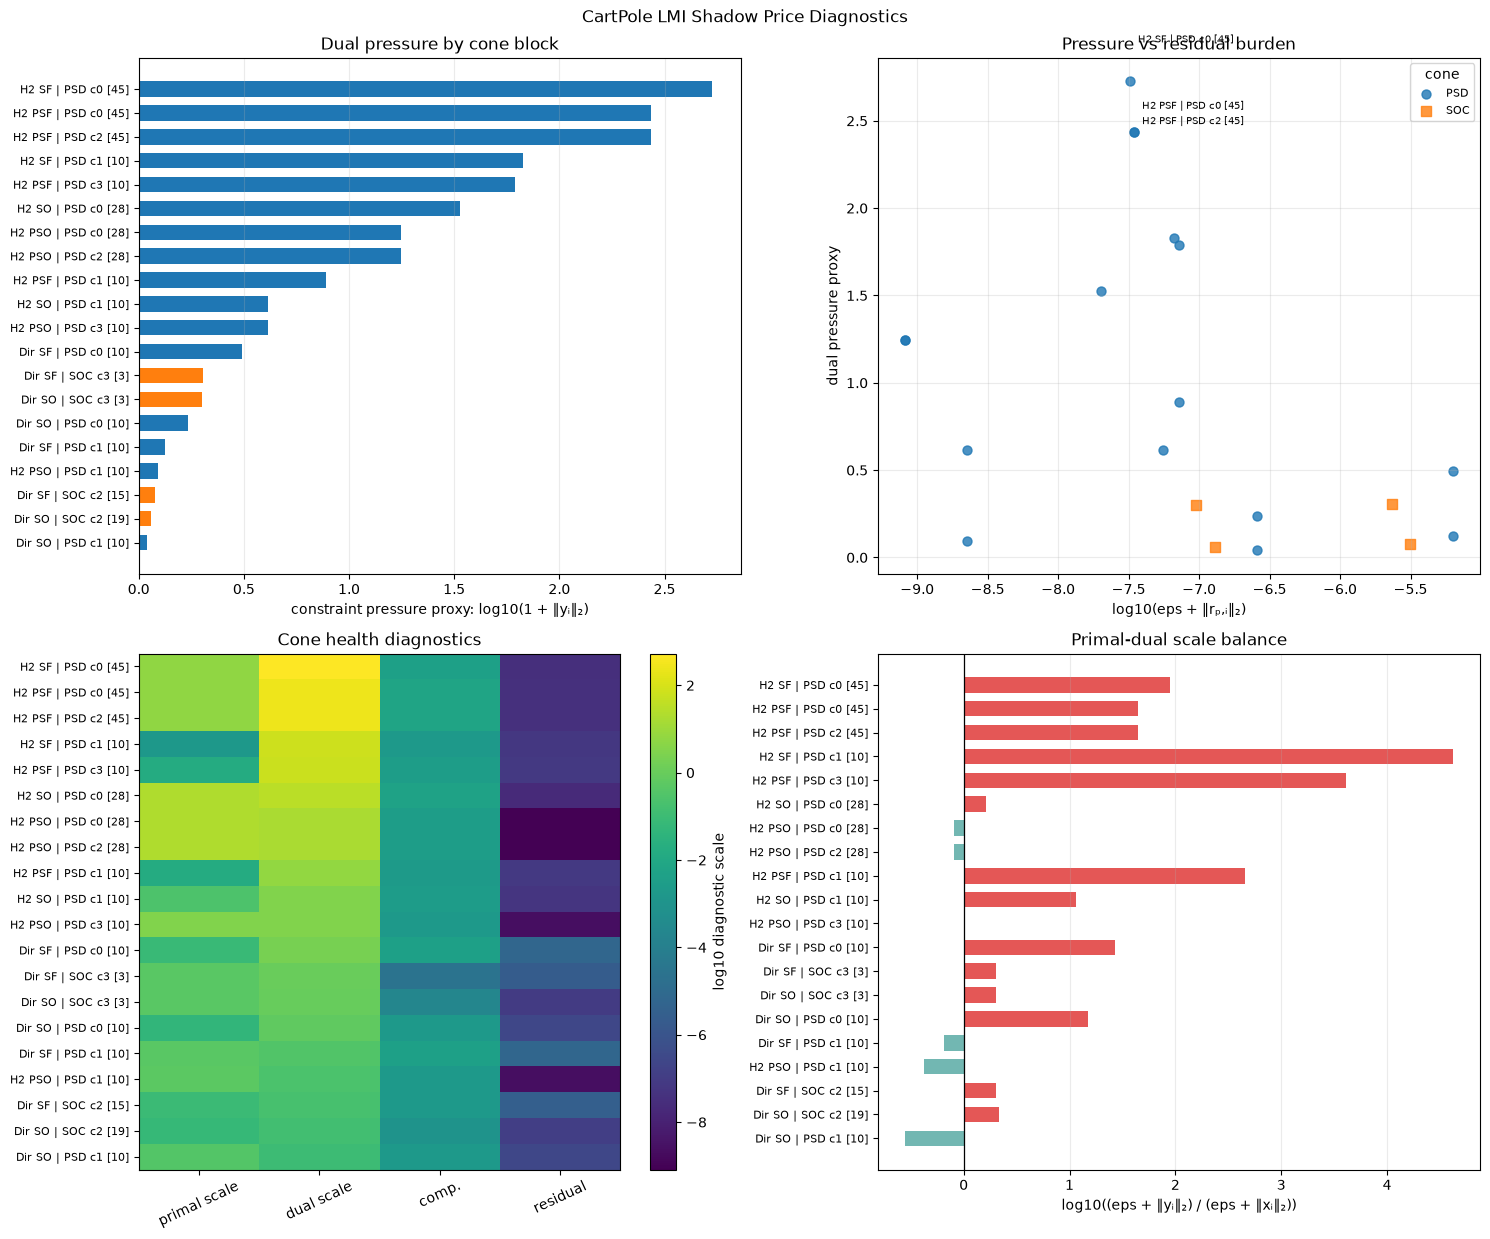

In [24]:
shadow_price_results = [
    ("state feedback", state_feedback_result),
    ("state observer", state_observer_result),
    ("H2 feedback", h2_feedback_result),
    ("H2 observer", observer_result),
    ("polytopic H2 feedback", poly_feedback_result),
    ("polytopic H2 observer", poly_observer_result),
]

plot_shadow_price_summary(
    shadow_price_results, title="CartPole LMI Shadow Price Diagnostics"
)

### Simulation and Results

Now we compare the packed dynamic compensators as actual closed-loop controllers. The controller takes the measured output $y=[x,\theta]^T$, produces a force command $u$, and the plant is also allowed to receive an external force disturbance $w$ through the same physical force channel.

For the Gymnasium rollouts, the binary action still carries the sign of the applied force, but the force magnitude is updated from the continuous controller output and clipped to Gymnasium's actuator limit. This is intentionally not pure fixed-magnitude bang-bang control, because fixed $\pm 10\,\mathrm{N}$ quantization makes small stabilizing commands behave like large impulses.

The simulations are staged in three passes:

1. Nominal dynamic compensators with force-step responses.
2. State trajectories and Gymnasium rollouts with an artificial force pulse.
3. The same rollout comparison while varying the pendulum mass.

In [25]:
def dynamic_compensator_specs():
    return [
        {
            "label": "LQG",
            "A": A - B @ K_lqr - L_lqe @ C,
            "B": L_lqe,
            "C": -K_lqr,
            "D": np.zeros((K_lqr.shape[0], C.shape[0])),
        },
        {
            "label": "H2",
            "A": A + B @ K_h2 - L_h2 @ C,
            "B": L_h2,
            "C": K_h2,
            "D": np.zeros((K_h2.shape[0], C.shape[0])),
        },
        {
            "label": "Polytopic H2",
            "A": A_h2_poly_compensator,
            "B": L_h2_poly,
            "C": K_h2_poly,
            "D": np.zeros((K_h2_poly.shape[0], C.shape[0])),
        },
    ]


def plant_plus_compensator_system(A_plant, B_plant, C_measure, controller):
    ctrl_state_count = controller["A"].shape[0]
    A_augmented = np.block(
        [
            [A_plant, B_plant @ controller["C"]],
            [controller["B"] @ C_measure, controller["A"]],
        ]
    )
    B_disturbance = np.vstack((B_plant, np.zeros((ctrl_state_count, B_plant.shape[1]))))
    C_state = np.hstack(
        (np.eye(A_plant.shape[0]), np.zeros((A_plant.shape[0], ctrl_state_count)))
    )
    D_state = np.zeros((A_plant.shape[0], B_plant.shape[1]))
    return ct.ss(A_augmented, B_disturbance, C_state, D_state)


def force_pulse(time, *, start=0.35, stop=0.75, amplitude=0.75):
    return amplitude * ((time >= start) & (time <= stop)).astype(float)


def simulate_system(system, time, disturbance):
    _, y_out = ct.forced_response(system, T=time, U=disturbance)
    return np.asarray(y_out).T


def discretize_controller(controller):
    controller_ss = ct.ss(
        controller["A"], controller["B"], controller["C"], controller["D"]
    )
    controller_d = ct.c2d(controller_ss, CARTPOLE_DT)
    return (
        np.asarray(controller_d.A),
        np.asarray(controller_d.B),
        np.asarray(controller_d.C),
        np.asarray(controller_d.D),
    )


def configure_pendulum_mass(env, mass):
    model = env.unwrapped
    model.masspole = float(mass)
    model.total_mass = model.masspole + model.masscart
    model.polemass_length = model.masspole * model.length


def run_gym_rollout(
    controller,
    *,
    init_state,
    pendulum_mass=mp,
    disturbance=None,
    steps=250,
    seed=42,
    max_force=10.0,
    capture_frames=False,
):
    render_mode = "rgb_array" if capture_frames else None
    env = gym.make("CartPole-v1", render_mode=render_mode)
    configure_pendulum_mass(env, pendulum_mass)
    env.reset(seed=seed)
    env.unwrapped.state = np.asarray(init_state, dtype=np.float64).copy()

    A_ctrl, B_ctrl, C_ctrl, D_ctrl = discretize_controller(controller)

    ctrl_state = np.zeros(A_ctrl.shape[0], dtype=np.float64)
    states, controls, frames = [], [], []

    for step in range(steps):
        state = np.asarray(env.unwrapped.state, dtype=np.float64)
        measurement = C @ state
        force_cmd = float((C_ctrl @ ctrl_state + D_ctrl @ measurement).squeeze())
        disturbance_force = (
            0.0 if disturbance is None else float(disturbance(step * CARTPOLE_DT))
        )
        applied_force = float(
            np.clip(force_cmd + disturbance_force, -max_force, max_force)
        )
        env.unwrapped.force_mag = abs(applied_force)
        action = 1 if applied_force >= 0.0 else 0

        if capture_frames:
            frames.append(env.rend())

        states.append(state.copy())
        controls.append(applied_force)

        _, _, terminated, truncated, _ = env.step(action)
        ctrl_state = A_ctrl @ ctrl_state + B_ctrl @ measurement

        if terminated or truncated:
            break

    env.close()
    return {
        "states": np.asarray(states),
        "controls": np.asarray(controls),
        "frames": frames,
    }

#### Forced Step Response Plot

Each augmented closed-loop system has one external disturbance input $w$ entering through the plant's physical force channel, with input matrix $B_{dist}=[B^T\;0^T]^T$. The plots below apply a persistent unit step, $w(t)=1\,\mathrm{N}$ for $t\geq0$, and show the resulting plant-state response while each dynamic compensator remains in the loop. This is a disturbance-rejection response, not a reference-tracking step response.

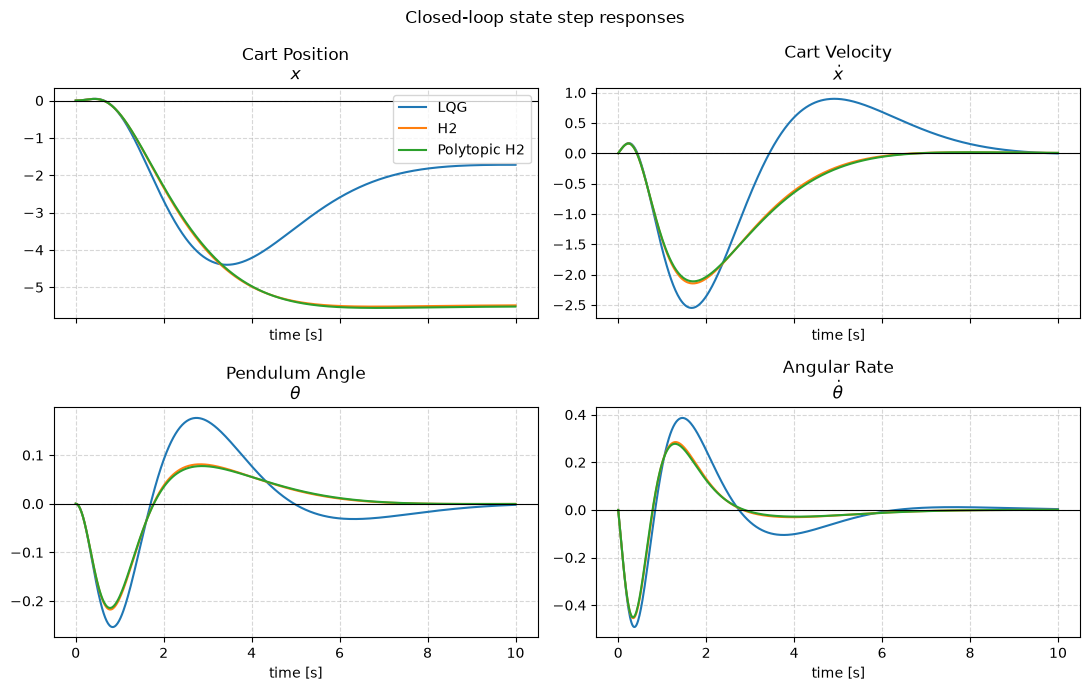

In [26]:
dynamic_compensators = dynamic_compensator_specs()
dynamic_labels = [ctrl["label"] for ctrl in dynamic_compensators]
dynamic_closed_loop_systems = [
    plant_plus_compensator_system(A, B, C, ctrl) for ctrl in dynamic_compensators
]

plot_state_step_responses(
    dynamic_closed_loop_systems,
    dynamic_labels,
    STATE_LABELS,
    T=np.linspace(0.0, 10.0, 600),
)

#### Linear State Trajectory Plots

Next, the persistent unit step is replaced by a finite rectangular force pulse through the same disturbance channel:

$$
w(t)=\begin{cases}0.75\,\mathrm{N}, & 0.35\leq t\leq0.75\,\mathrm{s},\\0, & \text{otherwise}.\end{cases}
$$

The pulse amplitude is constant during this interval; it does not ramp with time. The resulting trajectories show how each linear closed-loop plant is displaced by the pulse and then recovers after the disturbance is removed. The simulation grid uses step size $\Delta t$ over $0\,\mathrm{s} \leq t \leq 5\,\mathrm{s}$.

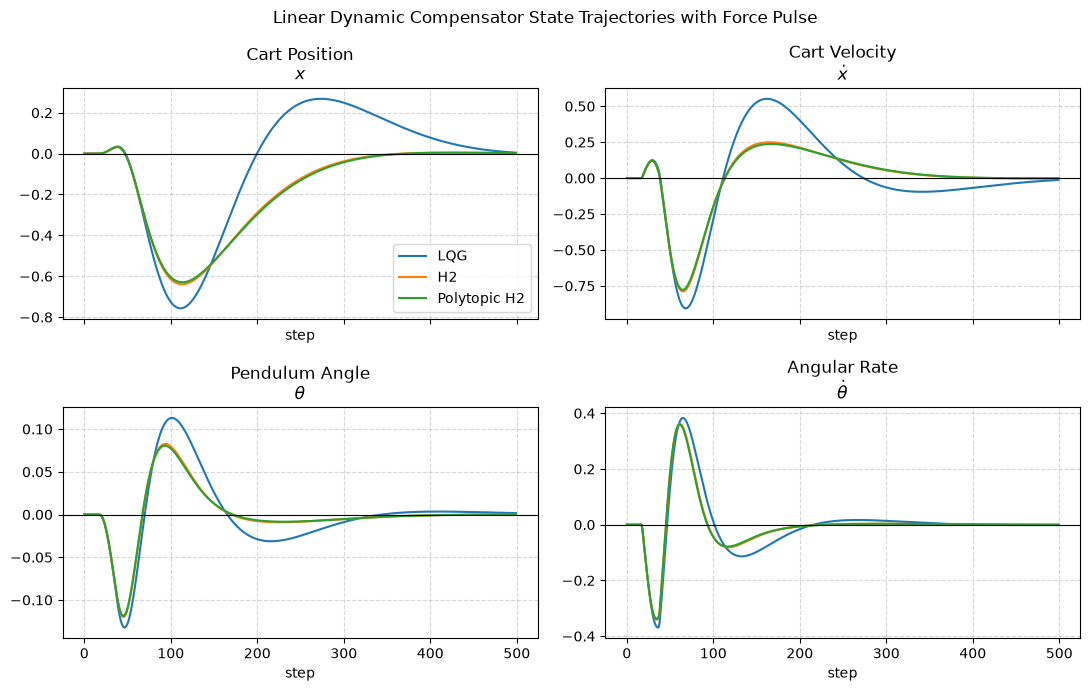

In [27]:
trajectory_time = np.arange(0.0, 10.0, CARTPOLE_DT)
disturbance_profile = force_pulse(trajectory_time)
disturbed_linear_trajectories = [
    simulate_system(system, trajectory_time, disturbance_profile)
    for system in dynamic_closed_loop_systems
]
plot_state_trajectories(
    disturbed_linear_trajectories,
    dynamic_labels,
    STATE_LABELS,
    "Linear Dynamic Compensator State Trajectories with Force Pulse",
)

#### Gymnasium Rollout with Disturbance

The resulting Gymnasium state trajectories under the same artificial force pulse are shown below.

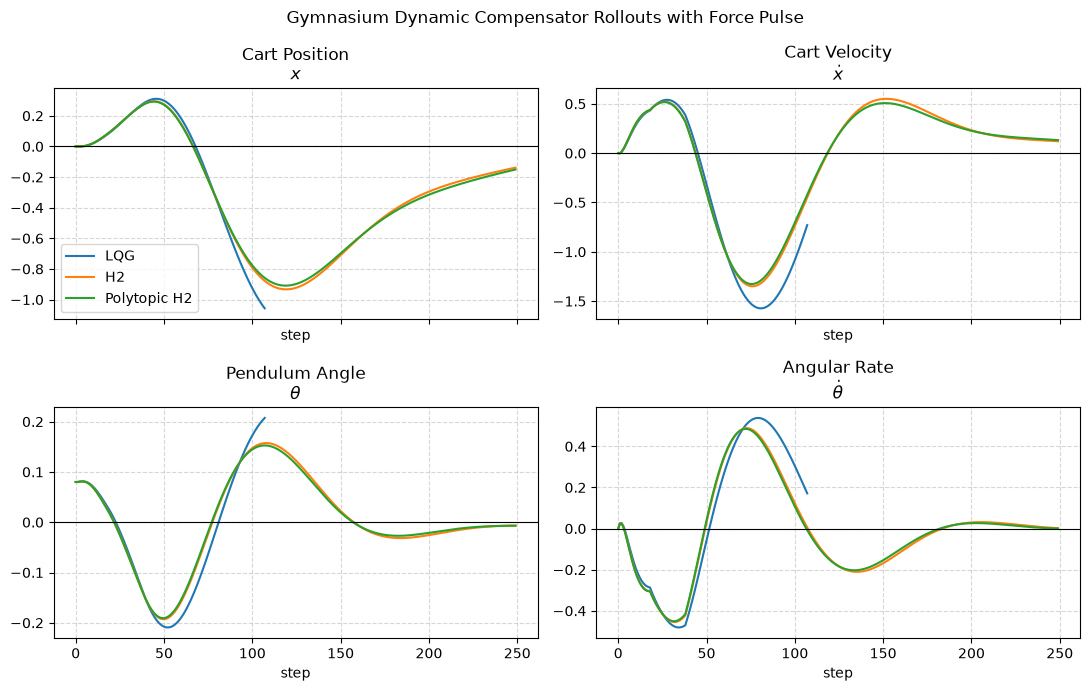

In [28]:
init_rollout_state = np.array([0.0, 0.0, 0.08, 0.0], dtype=np.float64)


def rollout_disturbance(time):
    return force_pulse(np.asarray([time]), amplitude=0.75)[0]


disturbed_rollouts = [
    run_gym_rollout(
        ctrl, init_state=init_rollout_state, disturbance=rollout_disturbance
    )
    for ctrl in dynamic_compensators
]
plot_rollout_states(
    disturbed_rollouts,
    dynamic_labels,
    STATE_LABELS,
    "Gymnasium Dynamic Compensator Rollouts with Force Pulse",
)

#### Pendulum Mass Variation in Gymnasium Rollout

The final simulation varies pendulum mass across the same $\pm15\%$ synthesis vertices while applying the force pulse. The endpoint pole plots show the local linear stability margins; these rollouts then show how those margins translate to the nonlinear Gymnasium dynamics.

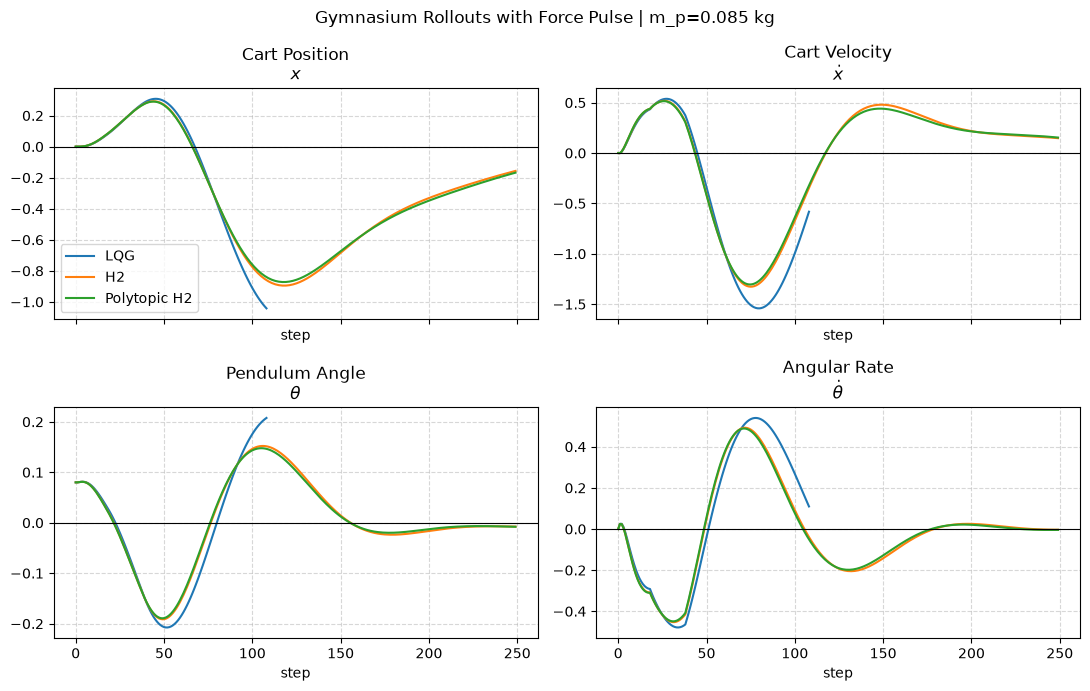

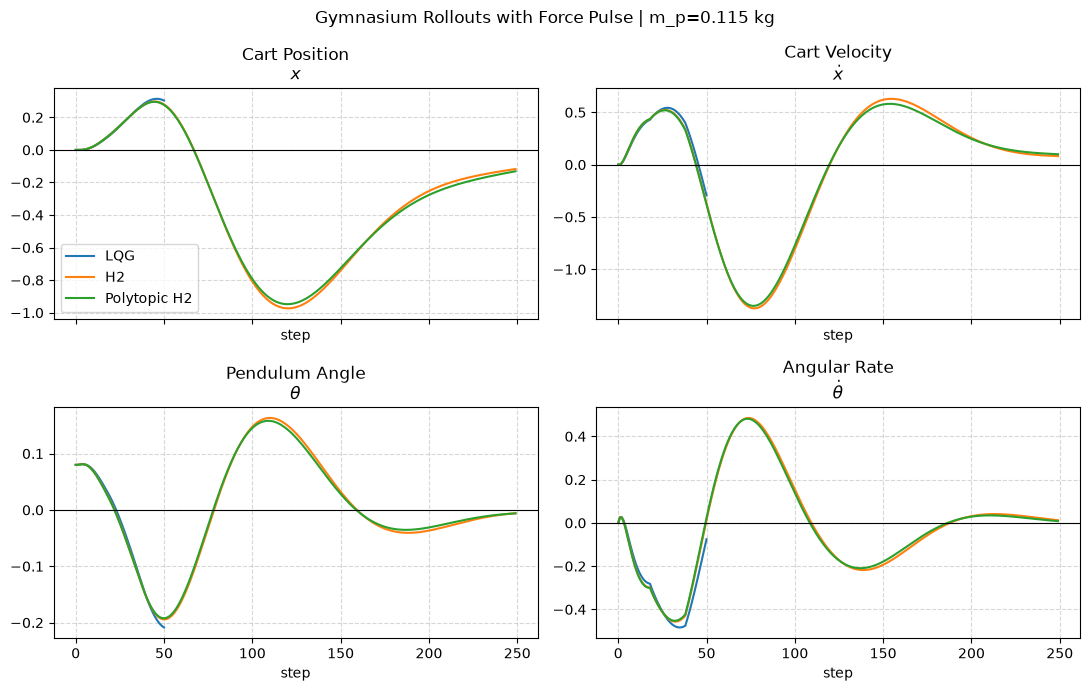

In [29]:
mass_variation_rollouts, mass_variation_labels = [], []
for mass in mp_vertices:
    mass_rollouts, mass_labels = [], []
    for ctrl in dynamic_compensators:
        mass_rollouts.append(
            run_gym_rollout(
                ctrl,
                init_state=init_rollout_state,
                pendulum_mass=mass,
                disturbance=rollout_disturbance,
            )
        )
        mass_labels.append(ctrl["label"])
    mass_variation_rollouts.append(mass_rollouts)
    mass_variation_labels.append(mass_labels)
    display(
        plot_rollout_states(
            mass_rollouts,
            mass_labels,
            STATE_LABELS,
            f"Gymnasium Rollouts with Force Pulse | m_p={mass:.3f} kg",
        )
    )

© 2026 Akreon LLC.

Licensed under the Apache License, Version 2.0. See [LICENSE](../../LICENSE).